# Visualização — subject S1

Etapa 03 – visualization: comparação gráfica entre dados de diferentes classes/eventos com parâmetros ajustáveis

1. compara mesma classe - mesma frequência de estímulo nos 4 blocos
2. compara classes distintas - média dos 4 blocos de cada classe
3. compara canais separadamente
4. olha trechos sem estímulo que podem servir depois como referencia de ruído

os gráficos usam o espectro PSD porque o SSVEP aparece como pico na frequência do estímulo e nos harmônicos

In [1]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
import mne

mne.set_log_level('WARNING')

ARQUIVO = 'processed/S1_pre-epo.fif'     # epoch gerada

# ajustavel
CLASSE_A = 8.0               # Hz (frequência de estímulo)
CLASSE_B = 12.0              # Hz
BLOCO = 0                    # epoch único usado nas comparações (0 a 3)

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})

In [2]:
epochs = mne.read_epochs(ARQUIVO)
FS = epochs.info['sfreq']
canais = epochs.ch_names
freqs = np.array([float(k.split()[0]) for k in sorted(epochs.event_id, key=epochs.event_id.get)])
estimulo = epochs.copy().crop(0, 2 - 1 / FS)      # janela de estímulo de 2 s (S1), 500 amostras


def nome(f):
    # nome da classe no event_id, ex.: 8.0 -> '8.0 Hz'
    return f'{freqs[np.argmin(np.abs(freqs - f))]:.1f} Hz'


def media_canais(ep):
    # sinal médio dos canais em µV: (epochs, amostras)
    return ep.get_data(units='uV').mean(axis=1)


def psd(x, n_per_seg=250):
    # PSD de Welch (janelas de 1 s, 50% de sobreposição) ao longo do último eixo. n_fft=1250 só interpola a
    # curva em passos de 0,2 Hz; a resolução real continua sendo 1 / duração da janela
    p, f = mne.time_frequency.psd_array_welch(x, FS, n_fft=1250, n_per_seg=n_per_seg,
                                              n_overlap=n_per_seg // 2, window='hann')
    return f, p


A, B = nome(CLASSE_A), nome(CLASSE_B)
print(epochs)
print(f"filtro: {epochs.info['description']} | canais: {canais}")
print(f"classe A: {A} | classe B: {B} | bloco: {BLOCO + 1}")

<EpochsFIF | 160 events (all good), -0.5 – 2.496 s (baseline off), ~8.3 MiB, data loaded,
 '8.6 Hz': 4
 '8.8 Hz': 4
 '9.0 Hz': 4
 '9.2 Hz': 4
 '9.4 Hz': 4
 '9.6 Hz': 4
 '9.8 Hz': 4
 '10.0 Hz': 4
 '10.2 Hz': 4
 '10.4 Hz': 4
 and 30 more events ...>
filtro: band-pass 6-90 Hz | canais: ['PZ', 'PO3', 'PO5', 'PO4', 'PO6', 'POZ', 'O1', 'OZ', 'O2']
classe A: 8.0 Hz | classe B: 12.0 Hz | bloco: 1


## 1. Mesma classe: 4 blocos da classe A

Cada linha é um ensaio (bloco) diferente da mesma frequência. Se o SSVEP é consistente, o pico em `f` (e em `2f`) aparece em todos

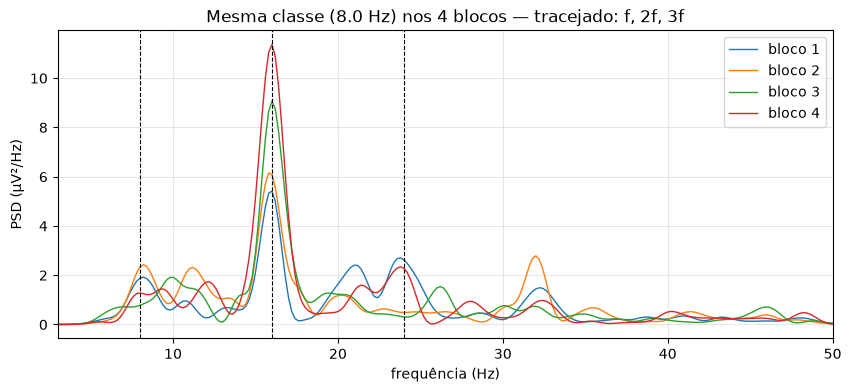

In [3]:
plt.figure(figsize=(10, 4))
f, p = psd(media_canais(estimulo[A]))                 # (4 blocos, freqs)
for b in range(4):
    plt.plot(f, p[b], lw=1, label=f'bloco {b + 1}')
for k in (1, 2, 3):
    plt.axvline(k * CLASSE_A, color='k', ls='--', lw=0.8)
plt.xlim(3, 50)
plt.xlabel('frequência (Hz)'); plt.ylabel('PSD (µV²/Hz)')
plt.title(f'Mesma classe ({A}) nos 4 blocos — tracejado: f, 2f, 3f')
plt.legend()
plt.show()

   - Os 4 blocos de 8,0 Hz mostram o pico no mesmo lugar, então a resposta é consistente entre repetições.
   - O pico mais forte não está em 8 Hz e sim em 16 Hz (2º harmônico). Isso é comum para estímulos baixos.
   - A altura do pico varia bastante entre blocos (de ~5 a ~11 µV²/Hz).

## 2. Classes distintas: A × B

media dos 4 blocos de cada classe onde cada classe deve ter pico na sua freq e não na de outra

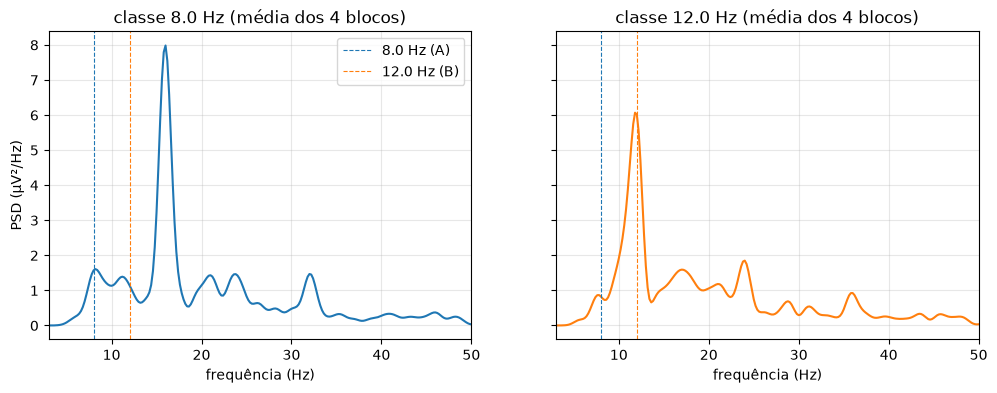

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, classe, cor in [(axs[0], A, 'tab:blue'), (axs[1], B, 'tab:orange')]:
    f, p = psd(media_canais(estimulo[classe]))
    ax.plot(f, p.mean(axis=0), color=cor)
    ax.axvline(CLASSE_A, color='tab:blue', ls='--', lw=0.8, label=f'{A} (A)')
    ax.axvline(CLASSE_B, color='tab:orange', ls='--', lw=0.8, label=f'{B} (B)')
    ax.set_xlim(3, 50); ax.set_xlabel('frequência (Hz)')
    ax.set_title(f'classe {classe} (média dos 4 blocos)')
axs[0].set_ylabel('PSD (µV²/Hz)'); axs[0].legend()
plt.show()

   - A classe de 12 Hz tem pico claro em 12 Hz e nenhum em 8 Hz.
   - A classe de 8 Hz tem pouco em 8 Hz e domina em 16 Hz.
   - Por isso um classificador precisa olhar harmônicos, não só a fundamental.

## 3. Classes distintas em cada canal

espectro médio dos 4 blocos de cada classe, canal a canal

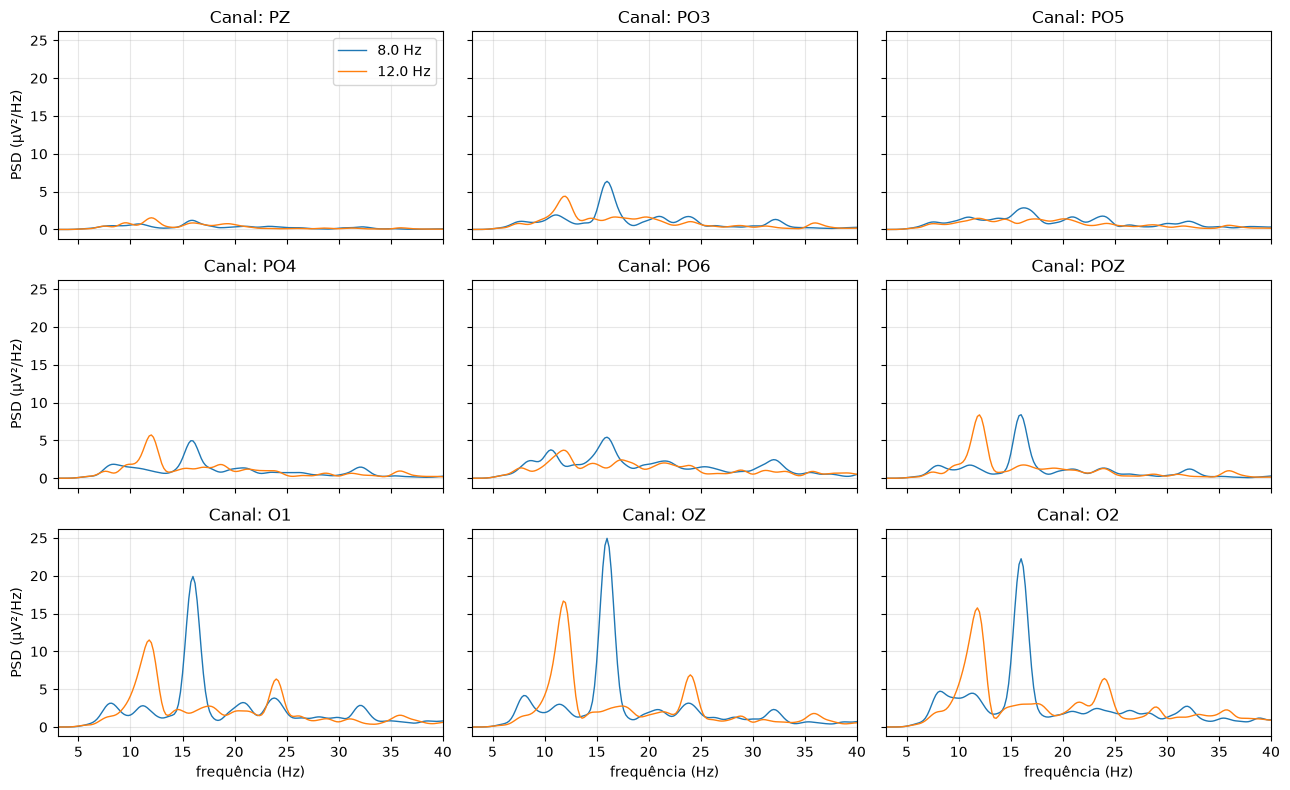

In [5]:
fig, axs = plt.subplots(3, 3, figsize=(13, 8), sharex=True, sharey=True)
espectros = {}
for classe in (A, B):
    spec = estimulo[classe].compute_psd(method='welch', n_fft=1250, n_per_seg=250, n_overlap=125,
                                        window='hann', fmax=40)
    p, f = spec.get_data(return_freqs=True)
    espectros[classe] = p.mean(axis=0) * 1e12                # média dos 4 blocos, µV²/Hz: (canais, freqs)
for i, ax in enumerate(axs.flat):
    for classe, cor in [(A, 'tab:blue'), (B, 'tab:orange')]:
        ax.plot(f, espectros[classe][i], color=cor, lw=1, label=classe)
    ax.set_title(f'Canal: {canais[i]}')
    ax.set_xlim(3, 40)
for ax in axs[:, 0]:
    ax.set_ylabel('PSD (µV²/Hz)')
for ax in axs[-1]:
    ax.set_xlabel('frequência (Hz)')
axs[0, 0].legend()
plt.tight_layout()
plt.show()

Para não depender de só duas classes: SNR de cada canal na frequência do estímulo (f) e no 2º harmônico (2f), média dos 160 ensaios. SNR = amplitude no bin da frequência ÷ média dos bins vizinhos (de 0,5 a 1 Hz de distância), em dB.

In [6]:
def snr(x, f0):
    # x: (epochs, amostras) da janela de estímulo; devolve SNR em dB por epoch
    espectro = np.abs(np.fft.rfft(x, n=1000, axis=1))
    f = np.fft.rfftfreq(1000, 1 / FS)
    k = np.argmin(np.abs(f - f0))
    vizinhos = np.r_[espectro[:, k - 4:k - 1].T, espectro[:, k + 2:k + 5].T].mean(axis=0)
    return 20 * np.log10(espectro[:, k] / vizinhos)


por_classe = {f0: estimulo[nome(f0)].get_data(units='uV') for f0 in freqs}     # (4, canais, amostras)
print(f"{'canal':6s} {'SNR f (dB)':>11s} {'SNR 2f (dB)':>12s}")
for i, n in enumerate(canais):
    s1 = np.concatenate([snr(x[:, i], f0) for f0, x in por_classe.items()])
    s2 = np.concatenate([snr(x[:, i], 2 * f0) for f0, x in por_classe.items()])
    print(f"{n:6s} {s1.mean():11.2f} {s2.mean():12.2f}")

canal   SNR f (dB)  SNR 2f (dB)
PZ            2.44         1.81
PO3           5.63         4.61
PO5           2.14         2.77
PO4           5.07         4.71
PO6           3.43         4.44
POZ           7.78         5.60
O1            8.48         8.55
OZ            9.65         9.15
O2            7.70         7.92


   - O SSVEP está concentrado em O1, OZ e O2: na classe de 8 Hz o pico de 16 Hz chega a ~20–25 µV²/Hz, e na de 12 Hz aparece também o harmônico de 24 Hz.
   - POZ é intermediário; PO3/PO4 são fracos; PZ, PO5 e PO6 quase não mostram pico.
   - O SNR médio dos 160 ensaios confirma a ordem: OZ 9,7 dB > O1 8,5 > POZ 7,8 ≈ O2 7,7 > PO3 5,6 > PO4 5,1 > PO6 3,4 > PZ 2,4 > PO5 2,1
   - Consequência: média simples dos 9 canais dá o mesmo peso pra canais quase sem resposta (PZ, PO5) e dilui o sinal. Isso favorece métodos que ponderam os canais

## 4. Com estímulo × sem estímulo

O trecho de 0,5 s antes do onset não tem estímulo. Comparar ele com 0,5 s de estímulo (mesma duração, para ser justo) mostra o que o estímulo acrescenta. O baseline pode servir depois como estimativa de ruído de fundo.

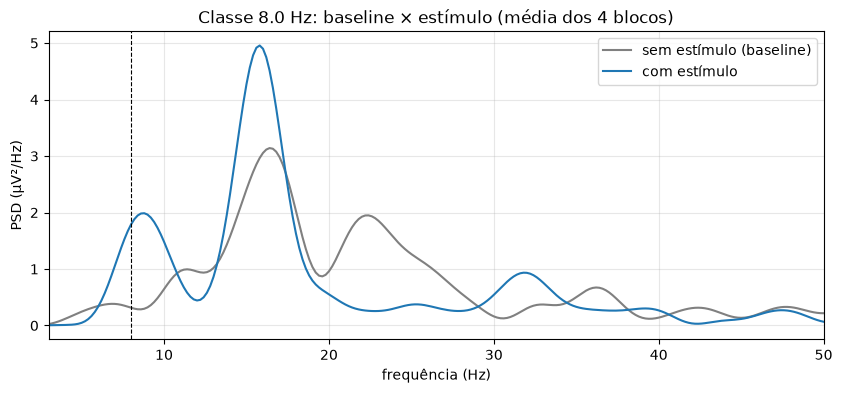

In [7]:
base = media_canais(epochs[A].copy().crop(-0.5, -1 / FS))       # 0,5 s sem estímulo
estim = media_canais(epochs[A].copy().crop(0.5, 1.0 - 1 / FS))   # 0,5 s de estímulo (de 0,5 a 1,0 s após o onset)

plt.figure(figsize=(10, 4))
for x, rotulo, cor in [(base, 'sem estímulo (baseline)', 'gray'), (estim, 'com estímulo', 'tab:blue')]:
    f, p = psd(x, n_per_seg=125)
    plt.plot(f, p.mean(axis=0), color=cor, label=rotulo)
plt.axvline(CLASSE_A, color='k', ls='--', lw=0.8)
plt.xlim(3, 50)
plt.xlabel('frequência (Hz)'); plt.ylabel('PSD (µV²/Hz)')
plt.title(f'Classe {A}: baseline × estímulo (média dos 4 blocos)')
plt.legend()
plt.show()

   - estímulo cria potência em 8–9 Hz que não existe no baseline.
   - baseline tem pico perto de 16 Hz. aparece só nessa classe (não é ritmo espontâneo do subject) e também no dado sem filtro 6–90.
   - Explicação provável: filtro de fase zero aplicado pelo BETA antes de cortar os ensaios "espalha" para trás no tempo parte da resposta forte de 16 Hz.
   - trecho pré-estimulo não é ruido de fundo totalmente limpo pra usar de referência

## 5. Três formas de estimar o espectro (1 ensaio)

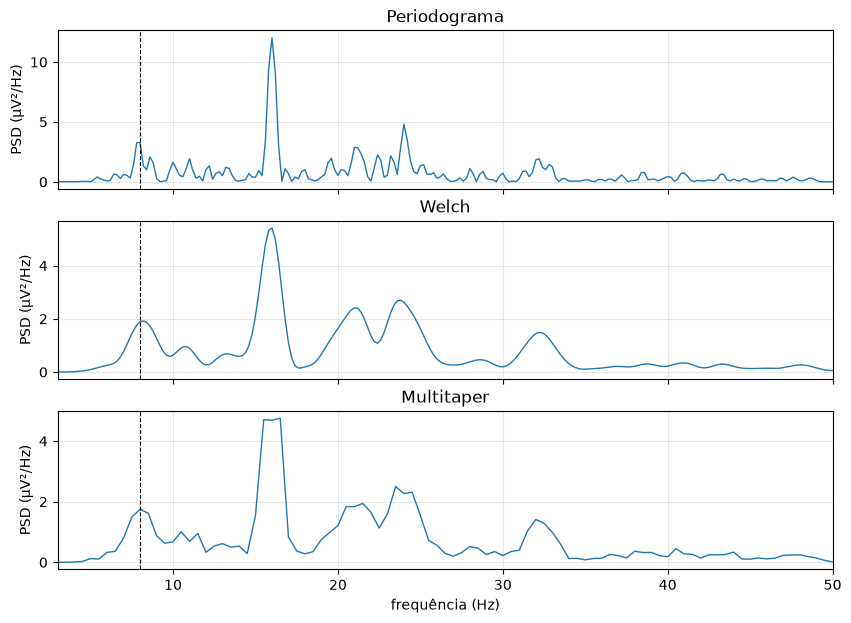

In [8]:
x = media_canais(estimulo[A][BLOCO])[0]       # um bloco da classe A

f1, p1 = signal.periodogram(x, fs=FS, nfft=1250)
f2, p2 = psd(x)
p3, f3 = mne.time_frequency.psd_array_multitaper(x, FS, bandwidth=2.0, normalization='full')

fig, axs = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, f, p, metodo in [(axs[0], f1, p1, 'Periodograma'), (axs[1], f2, p2, 'Welch'), (axs[2], f3, p3, 'Multitaper')]:
    ax.plot(f, p, lw=1)
    ax.axvline(CLASSE_A, color='k', ls='--', lw=0.8)
    ax.set_title(metodo); ax.set_ylabel('PSD (µV²/Hz)')
axs[2].set_xlim(3, 50); axs[2].set_xlabel('frequência (Hz)')
plt.show()

   - periodograma muito ruidoso
   - Welch suave e alarga picos
   - multitaper (banda 2 Hz) menos ruidoso que periodograma com mesmos picos do Welch (8, 16, ~24 e 32 Hz), com picos de topo achatado, cada um com largura da banda escolhida

## 6. O pico do espectro acerta a classe?

Para cada uma das 40 classes: frequência com maior potência entre 7 e 16 Hz (média dos 4 blocos) contra a frequência real do estímulo. Pontos na diagonal = classe identificada só pelo pico.

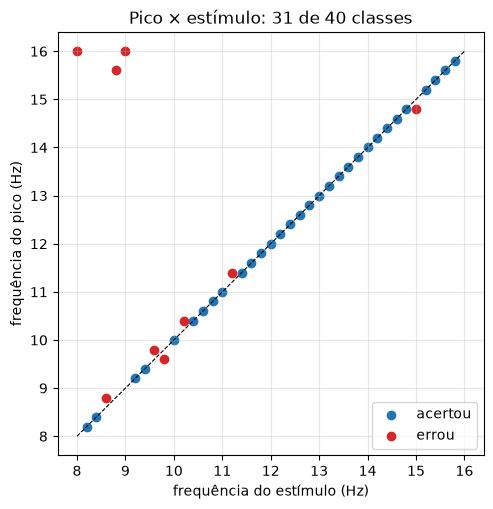

In [9]:
pico = []
for f0 in freqs:
    f, p = signal.periodogram(media_canais(estimulo[nome(f0)]), fs=FS, nfft=1250, axis=1)   # passo de 0,2 Hz
    p = p.mean(axis=0)                                                                      # média dos blocos
    faixa = (f >= 7) & (f <= 16)
    pico.append(f[faixa][np.argmax(p[faixa])])
pico = np.array(pico)
acertos = np.isclose(pico, freqs, atol=0.1)

plt.figure(figsize=(5.5, 5.5))
plt.plot([8, 16], [8, 16], 'k--', lw=0.8)
plt.scatter(freqs[acertos], pico[acertos], color='tab:blue', label='acertou')
plt.scatter(freqs[~acertos], pico[~acertos], color='tab:red', label='errou')
plt.xlabel('frequência do estímulo (Hz)'); plt.ylabel('frequência do pico (Hz)')
plt.title(f'Pico × estímulo: {acertos.sum()} de 40 classes')
plt.legend()
plt.show()

   - 31 de 40 classes são identificadas só pelo maior pico entre 7 e 16 Hz
   - 6 erros caem num vizinho a ~0,2 que seria a classe ao lado, é esperado ja que com 2s de sinal a resolução real do espectro é 1/2 s = 0,5 Hz. O `nfft=1250` só interpola a curva em passos de 0,2 Hz, não separa dois picos a 0,2 Hz
   - 3 erros (8,0, 8,8 e 9,0 Hz) caem perto de 16 Hz: em 8,0 Hz é o 2º harmônico, mais forte que a fundamental; nas outras duas o pico de 16 Hz supera uma fundamental fraca

O antes × depois do filtro está em `pre-processing.ipynb`